## 0. Setup

In [1]:
import os, math, random, glob, warnings
import numpy as np, pandas as pd, cv2
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE -------------------------
ROLL       = "23f1003053"
DATA_ROOT  = os.environ.get("DATA_ROOT", "/kaggle/input/competitions/industrial-surface-defect-detection/public")
USE_WANDB  = True            # set False to skip W&B logging (the form asks you to log every run, so keep True for submission)
# --------------------------------------------------------------

TRAIN_CSV = os.path.join(DATA_ROOT, "train.csv")
IMG_DIR   = os.path.join(DATA_ROOT, "train")

# fallback: search for train.csv if the path above is wrong
if not os.path.exists(TRAIN_CSV):
    hits = glob.glob("/kaggle/input/**/train.csv", recursive=True) + glob.glob("./**/train.csv", recursive=True)
    if hits:
        TRAIN_CSV = hits[0]; DATA_ROOT = os.path.dirname(TRAIN_CSV); IMG_DIR = os.path.join(DATA_ROOT, "train")
assert os.path.exists(TRAIN_CSV), f"train.csv not found -> set DATA_ROOT (tried {TRAIN_CSV})"
print("train.csv :", TRAIN_CSV)

H, W = 128, 800
HW = H * W                                   # 102,400
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
SEED = 42

ANS = {}                                     # collected form answers
def answer(q, text):
    ANS[q] = text
    print(f"\n>>> {q} ANSWER: {text}")

train.csv : /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv


## 1. Working subset, RLE decoding, combination strings, 80/20 split
* unique `image_id`s sorted in ASCII order → first **1,200** images → 4,800 image-class pairs
* masks decoded **column-major (Fortran), 1-based** on a 128×800 canvas, runs beyond 102,400 are **clipped**
* combination string = sorted present classes joined by `+`, or `clean`; combos with **< 3 images → `rare_other`**; 80/20 stratified split, `random_state=42` → **960 / 240**

In [2]:
df = pd.read_csv(TRAIN_CSV)
print(df.columns.tolist(), "| rows:", len(df))
# be tolerant to column naming
col_img  = "image_id"
col_cls  = "defect_type" if "defect_type" in df.columns else [c for c in df.columns if "type" in c.lower() or "class" in c.lower()][0]
col_rle  = "mask_rle"    if "mask_rle"    in df.columns else [c for c in df.columns if "rle" in c.lower() or "mask" in c.lower()][0]

ids_all = sorted(df[col_img].astype(str).unique())            # Python str sort == ASCII order
ids = ids_all[:1200]
sub = df[df[col_img].astype(str).isin(set(ids))].copy()
print("subset rows:", len(sub), "| unique images:", sub[col_img].nunique())
assert len(ids) == 1200 and len(sub) == 4800, "subset must have 1,200 images / 4,800 rows"

def rle_decode(rle, h=H, w=W):
    flat = np.zeros(h * w, dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        s = np.array(rle.split(), dtype=np.int64)
        starts, lens = s[0::2] - 1, s[1::2]                    # 1-based -> 0-based
        for st, ln in zip(starts, lens):
            if st < 0 or st >= h * w: continue
            flat[st:min(st + ln, h * w)] = 1                   # clip anything beyond 102,400
    return flat.reshape((h, w), order="F")                     # Fortran / column-major

lookup = {(str(r[0]), r[1]): r[2] for r in zip(sub[col_img], sub[col_cls], sub[col_rle])}
masks = {i: np.stack([rle_decode(lookup.get((i, c))) for c in CLASSES]) for i in ids}   # (4,H,W) per image
print("decoded masks for", len(masks), "images")

['image_id', 'defect_type', 'mask_rle', 'width', 'height'] | rows: 45572
subset rows: 4800 | unique images: 1200
decoded masks for 1200 images


In [3]:
def combo_of(i):
    present = [c for k, c in enumerate(CLASSES) if masks[i][k].any()]
    return "+".join(present) if present else "clean"

combo_df = pd.DataFrame({"image_id": ids})
combo_df["combo"] = combo_df.image_id.map(combo_of)
combo_cnt = combo_df["combo"].value_counts()
combo_df["strat"] = np.where(combo_df["combo"].map(combo_cnt) >= 3, combo_df["combo"], "rare_other")
combo_map = dict(zip(combo_df.image_id, combo_df.combo))

print(combo_cnt.to_string(), "\n")
print("images merged into rare_other:", int((combo_df.strat == "rare_other").sum()))

train_ids, val_ids = train_test_split(combo_df.image_id.tolist(), test_size=0.2,
                                      random_state=42, stratify=combo_df["strat"])
print("train / val:", len(train_ids), "/", len(val_ids))
assert (len(train_ids), len(val_ids)) == (960, 240), "split should be 960/240"

G_val = np.stack([masks[i] for i in val_ids]).astype(np.uint8)      # (240,4,H,W) ground truth for validation

combo
clean                         578
defect_c                      334
defect_d                       81
defect_c+defect_d              71
defect_a                       59
defect_b                       22
defect_a+defect_c              21
defect_a+defect_d              14
defect_a+defect_c+defect_d      7
defect_b+defect_d               3
defect_a+defect_b+defect_d      3
defect_a+defect_b               2
defect_b+defect_c+defect_d      2
defect_b+defect_c               2
defect_a+defect_b+defect_c      1 

images merged into rare_other: 7
train / val: 960 / 240


## Question 1 — Image-level and class-level imbalance (full 1,200-image subset)

In [4]:
a_clean = int((combo_df.combo == "clean").sum())
b_cls   = [int(sum(masks[i][k].any() for i in ids)) for k in range(4)]
c_combo = int(combo_cnt.shape[0])                      # unique combination strings BEFORE merging
d_max, d_min = int(combo_cnt.max()), int(combo_cnt.min())

print("(a) clean images           :", a_clean)
print("(b) positives a/b/c/d      :", b_cls)
print("(c) unique combo strings   :", c_combo)
print("(d) largest / smallest grp :", d_max, d_min)
answer("Q1", f"{a_clean}; {b_cls[0]}, {b_cls[1]}, {b_cls[2]}, {b_cls[3]}; {c_combo}; {d_max}, {d_min}")

(a) clean images           : 578
(b) positives a/b/c/d      : [107, 35, 438, 181]
(c) unique combo strings   : 15
(d) largest / smallest grp : 578 1

>>> Q1 ANSWER: 578; 107, 35, 438, 181; 15; 578, 1


## Question 2 — Pixel-level imbalance and `pos_weight` (defect_b)

In [5]:
kb = CLASSES.index("defect_b")
areas_b = np.array([int(masks[i][kb].sum()) for i in ids])
pos_px  = int(areas_b.sum());  tot_px = len(ids) * HW
neg_px  = tot_px - pos_px

q2a = 100.0 * pos_px / tot_px                          # % positive pixels
q2b = areas_b[areas_b > 0].mean()                      # mean area among defect_b-positive images
q2c = neg_px / pos_px                                  # neg/pos ratio

print(f"(a) positive pixel %          : {q2a:.4f}")
print(f"(b) mean area (positive imgs) : {q2b:.1f}")
print(f"(c) neg/pos ratio             : {q2c:.2f} -> {round(q2c)}")
answer("Q2", f"{q2a:.4f}, {q2b:.1f}, {int(round(q2c))}")

(a) positive pixel %          : 0.0160
(b) mean area (positive imgs) : 561.5
(c) neg/pos ratio             : 6251.16 -> 6251

>>> Q2 ANSWER: 0.0160, 561.5, 6251


## Question 3 — Bounded square-root sampling
Group weight $w_g=\min\!\big(\sqrt{n_{clean}/n_g},\,5\big)$ over the **unmerged** combination groups of all 1,200 images; 1,200 draws per epoch with replacement.

In [6]:
n_clean = int(combo_cnt["clean"])
w_group = {g: min(math.sqrt(n_clean / n), 5.0) for g, n in combo_cnt.items()}        # clean -> 1.0
mass    = {g: combo_cnt[g] * w_group[g] for g in combo_cnt.index}                    # total sampling mass per group
Z       = sum(mass.values())

# (a) fraction of clean draws
a_samp, a_nat = 100 * mass["clean"] / Z, 100 * n_clean / len(ids)

# (b) expected defect_b-positive draws per epoch (any group containing defect_b)
b_groups = [g for g in combo_cnt.index if "defect_b" in g]
b_samp = 1200 * sum(mass[g] for g in b_groups) / Z
b_nat  = 1200 * sum(combo_cnt[g] for g in b_groups) / len(ids)

# (c) enrichment factor
c_enrich = b_samp / b_nat

# (d) groups hitting the cap (sqrt ratio >= 5, i.e. n_g <= n_clean/25)
raw = {g: math.sqrt(n_clean / n) for g, n in combo_cnt.items()}
d_cap     = sum(v >= 5.0 for v in raw.values())
d_cap_str = sum(v >  5.0 for v in raw.values())

print(f"n_clean = {n_clean}, groups = {len(combo_cnt)}")
print(f"(a) clean draws: sampler {a_samp:.2f}% vs natural {a_nat:.2f}%")
print(f"(b) defect_b draws/epoch: sampler {b_samp:.2f} vs natural {b_nat:.2f}")
print(f"(c) enrichment: {c_enrich:.2f}x")
print(f"(d) groups at cap: {d_cap}   (strictly above the cap: {d_cap_str}; they differ only if some group has exactly ratio 25)")
answer("Q3", f"{a_samp:.2f}, {a_nat:.2f}; {b_samp:.2f}, {b_nat:.2f}; {c_enrich:.2f}; {d_cap}")

n_clean = 578, groups = 15
(a) clean draws: sampler 28.81% vs natural 48.17%
(b) defect_b draws/epoch: sampler 104.69 vs natural 35.00
(c) enrichment: 2.99x
(d) groups at cap: 10   (strictly above the cap: 10; they differ only if some group has exactly ratio 25)

>>> Q3 ANSWER: 28.81, 48.17; 104.69, 35.00; 2.99; 10


## Question 4 — Warmup + cosine, and the stepping-cadence trap
60 optimizer steps/epoch, 8 epochs = 480 steps, base LR $3\times10^{-4}$; $m(t)=t/60$ for $t<60$, else $0.5\,(1+\cos(\pi\,(t-60)/420))$.

In [7]:
BASE_LR, WU, TOT = 3e-4, 60, 480
def m_q4(t):
    return t / WU if t < WU else 0.5 * (1 + math.cos(math.pi * (t - WU) / (TOT - WU)))
lr_at = lambda t: BASE_LR * m_q4(t)

lr15, lr270, lr400 = lr_at(15), lr_at(270), lr_at(400)
# bug: schedule written in STEPS but scheduler.step() called once per EPOCH -> after epoch 8, t = 8
lr_bug = lr_at(8)

print(f"(a) lr@15={lr15:.3e}  lr@270={lr270:.3e}  lr@400={lr400:.3e}")
print(f"(b) LR after epoch 8 with per-epoch stepping (t=8): {lr_bug:.3e}")
q4c = ("The LR stays stuck in the tiny warmup range (about 4e-5 at the end, never reaching 3e-4 and never decaying), "
       "so the loss falls very slowly and the model underfits with a flat LR curve and no cosine shape.")
print("(c)", q4c)
answer("Q4", f"{lr15:.2e}, {lr270:.2e}, {lr400:.2e}; {lr_bug:.2e}; {q4c}")

(a) lr@15=7.500e-05  lr@270=1.500e-04  lr@400=2.606e-05
(b) LR after epoch 8 with per-epoch stepping (t=8): 4.000e-05
(c) The LR stays stuck in the tiny warmup range (about 4e-5 at the end, never reaching 3e-4 and never decaying), so the loss falls very slowly and the model underfits with a flat LR curve and no cosine shape.

>>> Q4 ANSWER: 7.50e-05, 1.50e-04, 2.61e-05; 4.00e-05; The LR stays stuck in the tiny warmup range (about 4e-5 at the end, never reaching 3e-4 and never decaying), so the loss falls very slowly and the model underfits with a flat LR curve and no cosine shape.


## Question 5 — Early-stopping trace (patience 3, min_delta 0.002, mode = max)

In [8]:
scores = [0.512, 0.601, 0.648, 0.661, 0.664, 0.668, 0.671, 0.670, 0.672, 0.669, 0.673, 0.665]

def trace(scores, patience, min_delta, verbose=False):
    best, best_ep, bad, stop_ep = -float("inf"), None, 0, None
    for ep, s in enumerate(scores, 1):
        if s > best + min_delta:               # improvement -> save checkpoint, reset counter
            best, best_ep, bad = s, ep, 0; tag = "improved"
        else:
            bad += 1; tag = f"no improvement (bad={bad})"
        if verbose: print(f"ep {ep:2d}  score {s:.3f}  best {best:.3f}@{best_ep}  {tag}")
        if bad >= patience:
            stop_ep = ep; break
    return stop_ep, best_ep, best

print("--- min_delta = 0.002 ---")
e_stop, e_rest, s_rest = trace(scores, 3, 0.002, verbose=True)
print("\n--- min_delta = 0 ---")
stop0, best0, _ = trace(scores, 3, 0.0, verbose=True)

print(f"\n(a) stop at epoch {e_stop}, restore epoch {e_rest}, score {s_rest:.3f}")
print(f"(b) min_delta=0 stops within 12 epochs? {'yes' if stop0 else 'no'} ; best checkpoint at epoch 12 is epoch {best0}")
answer("Q5", f"{e_stop}, {e_rest}, {s_rest:.3f}; {'yes' if stop0 else 'no'}, {best0}")

--- min_delta = 0.002 ---
ep  1  score 0.512  best 0.512@1  improved
ep  2  score 0.601  best 0.601@2  improved
ep  3  score 0.648  best 0.648@3  improved
ep  4  score 0.661  best 0.661@4  improved
ep  5  score 0.664  best 0.664@5  improved
ep  6  score 0.668  best 0.668@6  improved
ep  7  score 0.671  best 0.671@7  improved
ep  8  score 0.670  best 0.671@7  no improvement (bad=1)
ep  9  score 0.672  best 0.671@7  no improvement (bad=2)
ep 10  score 0.669  best 0.671@7  no improvement (bad=3)

--- min_delta = 0 ---
ep  1  score 0.512  best 0.512@1  improved
ep  2  score 0.601  best 0.601@2  improved
ep  3  score 0.648  best 0.648@3  improved
ep  4  score 0.661  best 0.661@4  improved
ep  5  score 0.664  best 0.664@5  improved
ep  6  score 0.668  best 0.668@6  improved
ep  7  score 0.671  best 0.671@7  improved
ep  8  score 0.670  best 0.671@7  no improvement (bad=1)
ep  9  score 0.672  best 0.672@9  improved
ep 10  score 0.669  best 0.672@9  no improvement (bad=1)
ep 11  score 0.673  b

## Question 6 — Mixed precision, GPU memory and gradient accumulation

In [9]:
P_PARAMS = 25_000_000
MB = 1e6
# Part A
static_mb = P_PARAMS * 4 * (1 + 1 + 2) / MB            # weights + grads + 2 AdamW moments, all FP32
act_fp32, act_amp = 150.0, 75.0                         # MB per sample
tot = lambda bs, act: static_mb + bs * act
b_fp32, b_amp = tot(16, act_fp32), tot(16, act_amp)
c_fp32 = int((3400 - static_mb) // act_fp32)
c_amp  = int((3400 - static_mb) // act_amp)

# Part B
N_TRAIN, MICRO, ACC = 960, 8, 4
assert N_TRAIN % MICRO == 0 and (N_TRAIN // MICRO) % ACC == 0      # no partial last batch
d_eff   = MICRO * ACC
e_micro = N_TRAIN // MICRO
e_steps = e_micro // ACC
f_div   = ACC
g_warm  = 2 * e_steps

print(f"(a) weights+grads+AdamW = {static_mb:.0f} MB")
print(f"(b) bs16: FP32 {b_fp32:.0f} MB | AMP {b_amp:.0f} MB")
print(f"(c) max batch in 3400 MB: FP32 {c_fp32} | AMP {c_amp}")
print(f"(d) effective batch = {d_eff}")
print(f"(e) micro-batches/epoch = {e_micro}, optimizer steps/epoch = {e_steps}")
print(f"(f) divide each micro-batch loss by {f_div}")
print(f"(g) 2-epoch warmup = {g_warm} optimizer steps")
answer("Q6", f"{static_mb:.0f}; {b_fp32:.0f}, {b_amp:.0f}; {c_fp32}, {c_amp}; {d_eff}; {e_micro}, {e_steps}; {f_div}; {g_warm}")

(a) weights+grads+AdamW = 400 MB
(b) bs16: FP32 2800 MB | AMP 1600 MB
(c) max batch in 3400 MB: FP32 20 | AMP 40
(d) effective batch = 32
(e) micro-batches/epoch = 120, optimizer steps/epoch = 30
(f) divide each micro-batch loss by 4
(g) 2-epoch warmup = 60 optimizer steps

>>> Q6 ANSWER: 400; 2800, 1600; 20, 40; 32; 120, 30; 4; 60


## Metrics (used by Q7, Q8, Q10)
Empty-pair convention: Dice(∅,∅)=1, Dice(∅, non-empty)=0.

Official score $=0.70\cdot$ForegroundDice $+0.20\cdot$FalsePositiveScore $+0.10\cdot$EmptyAccuracy, computed per image-class **pair**:
* ForegroundDice = mean Dice over pairs whose ground truth is non-empty
* FalsePositiveScore = $1-\text{mean}(|P|/102{,}400)$ over empty-GT pairs
* EmptyAccuracy = share of empty-GT pairs predicted fully empty

*Naive empty-aware mean Dice* = mean Dice over **all** pairs with the empty-pair convention.

In [10]:
def pair_stats(P, G):
    # P, G: (N,4,H,W) {0,1}. Returns per-pair predicted size, gt size and Dice (empty convention)
    P = P.reshape(P.shape[0], 4, -1).astype(bool); G = G.reshape(G.shape[0], 4, -1).astype(bool)
    p_sz, g_sz = P.sum(-1).astype(np.int64), G.sum(-1).astype(np.int64)
    inter = (P & G).sum(-1).astype(np.int64)
    denom = p_sz + g_sz
    dice  = np.where(denom == 0, 1.0, 2.0 * inter / np.maximum(denom, 1))
    return p_sz, g_sz, dice

def official_score(P, G):
    p_sz, g_sz, dice = pair_stats(P, G)
    pos, emp = g_sz > 0, g_sz == 0
    fg  = dice[pos].mean() if pos.any() else 0.0
    fps = 1.0 - (p_sz[emp] / HW).mean() if emp.any() else 1.0
    ea  = (p_sz[emp] == 0).mean() if emp.any() else 1.0
    return 0.7 * fg + 0.2 * fps + 0.1 * ea, fg, fps, ea

def naive_dice(P, G):
    return float(pair_stats(P, G)[2].mean())

def false_alarm_rate(P, G):
    p_sz, g_sz, _ = pair_stats(P, G)
    emp = g_sz == 0
    return float((p_sz[emp] > 0).mean())

## Question 7 — The Naive Dice trap

In [11]:
# ---------- Part A: all-empty baseline on the 4,800 pairs of the 1,200-image subset ----------
G_all = np.stack([masks[i] for i in ids]).astype(np.uint8)
P_all_empty = np.zeros_like(G_all)
q7a = int((G_all.reshape(len(ids), 4, -1).sum(-1) == 0).sum())          # (a) empty ground-truth pairs
q7b = naive_dice(P_all_empty, G_all)                                    # (b) naive empty-aware mean Dice
q7c = official_score(P_all_empty, G_all)[0]                             # (c) official score
print(f"(a) empty-GT pairs        : {q7a} of {len(ids)*4}")
print(f"(b) baseline naive Dice   : {q7b:.4f}")
print(f"(c) baseline official     : {q7c:.4f}")
del G_all, P_all_empty

# ---------- Part B: toy validation set (400 pairs: 60 positive, 340 empty) ----------
n_pos, n_emp, fg_dice = 60, 340, 0.50
n_ok, n_blob, blob_px = 306, 34, 1024                                   # 306 predicted empty, 34 with a 1,024-px blob
fp_score = 1 - (n_blob * blob_px / HW) / n_emp
emp_acc  = n_ok / n_emp
d_off    = 0.7 * fg_dice + 0.2 * fp_score + 0.1 * emp_acc
d_naive  = (n_pos * fg_dice + n_ok * 1.0 + n_blob * 0.0) / (n_pos + n_emp)
base_naive = n_emp * 1.0 / (n_pos + n_emp)                              # all-empty baseline: 340 perfect empties, 60 zeros
base_off   = 0.7 * 0 + 0.2 * 1 + 0.1 * 1
print(f"\n(d) model official {d_off:.4f} | model naive {d_naive:.4f}")
print(f"(e) baseline naive {base_naive:.4f} (> model {d_naive:.4f}) while baseline official is only {base_off:.4f}")
assert base_naive > d_naive and base_off < d_off
answer("Q7", f"{q7a}; {q7b:.4f}, {q7c:.4f}; {d_off:.4f}, {d_naive:.4f}; Naive Dice, {base_naive:.4f}")

(a) empty-GT pairs        : 4039 of 4800
(b) baseline naive Dice   : 0.8415
(c) baseline official     : 0.3000

(d) model official 0.6398 | model naive 0.8400
(e) baseline naive 0.8500 (> model 0.8400) while baseline official is only 0.3000

>>> Q7 ANSWER: 4039; 0.8415, 0.3000; 0.6398, 0.8400; Naive Dice, 0.8500


## Question 9 — Defect-size binning, presence vs. overlap

In [12]:
pos_area = np.array([int(masks[i][k].sum()) for i in ids for k in range(4) if masks[i][k].any()])
bins   = {"1-100": (1, 100), "101-500": (101, 500), "501+": (501, 10**9)}
cnt    = {b: int(((pos_area >= lo) & (pos_area <= hi)).sum()) for b, (lo, hi) in bins.items()}
px_bin = {b: int(pos_area[(pos_area >= lo) & (pos_area <= hi)].sum()) for b, (lo, hi) in bins.items()}
assert sum(cnt.values()) == len(pos_area)

q9b = 100 * px_bin["501+"] / pos_area.sum()
recall = {"1-100": 0.30, "101-500": 0.70, "501+": 0.95}
missed = {b: cnt[b] * (1 - recall[b]) for b in bins}
q9c, q9c_bin = sum(missed.values()), max(missed, key=missed.get)

print("(a) positive pairs per bin :", cnt, "| total positive pairs:", len(pos_area))
print("(b) % of positive pixels in 501+ :", f"{q9b:.2f}", "| pixels per bin:", px_bin)
print("(c) expected missed pairs per bin:", {k: round(v, 2) for k, v in missed.items()}, f"-> total {q9c:.2f}, most: {q9c_bin}")
q9d = ("Missed pairs count every defect equally regardless of size, whereas missed pixels are dominated by the few large defects "
       "that hold most of the pixels, so the bin with the most small/numerous defects can lose the most pairs while a different bin loses the most pixels.")
answer("Q9", f"{cnt['1-100']}, {cnt['101-500']}, {cnt['501+']}; {q9b:.2f}; {q9c:.2f}, {q9c_bin}; {q9d}")

(a) positive pairs per bin : {'1-100': 5, '101-500': 99, '501+': 657} | total positive pairs: 761
(b) % of positive pixels in 501+ : 99.24 | pixels per bin: {'1-100': 298, '101-500': 29996, '501+': 3953580}
(c) expected missed pairs per bin: {'1-100': 3.5, '101-500': 29.7, '501+': 32.85} -> total 66.05, most: 501+

>>> Q9 ANSWER: 5, 99, 657; 99.24; 66.05, 501+; Missed pairs count every defect equally regardless of size, whereas missed pixels are dominated by the few large defects that hold most of the pixels, so the bin with the most small/numerous defects can lose the most pairs while a different bin loses the most pixels.


## 8. Training engine (needed for Q8 and Q10)
U-Net (ResNet-34, 1-ch input, 4-ch output), BCE-with-logits, **AdamW lr 3e-4, batch 16, AMP on, native 128×800, threshold 0.5, no min-area filtering, 6 epochs**.
Per epoch it logs **train loss, validation loss and the official validation score** to W&B project `23f1003053-t32026`.
The checkpoint kept is the epoch with the highest official validation score (its binary predictions are stored for the false-alarm analysis).

In [13]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
try:
    import segmentation_models_pytorch as smp
except ImportError:
    os.system("pip install -q segmentation-models-pytorch"); import segmentation_models_pytorch as smp
try:
    import wandb
except ImportError:
    os.system("pip install -q wandb"); import wandb

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV)
if DEV == "cpu": print("WARNING: no GPU detected - 4 trainings on CPU will be very slow.")

if USE_WANDB:
    try:
        from kaggle_secrets import UserSecretsClient
        wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
    except Exception as e:
        print("Kaggle secret not used ->", type(e).__name__, "-> trying wandb.login()")
        try: wandb.login()
        except Exception as e2:
            print("W&B login failed -> logging disabled:", type(e2).__name__); USE_WANDB = False

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# ---- images (cached as uint8) ----
_exts = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
assert os.path.isdir(IMG_DIR), f"image folder not found: {IMG_DIR}"
path_index = {os.path.splitext(f)[0]: os.path.join(IMG_DIR, f) for f in os.listdir(IMG_DIR) if f.lower().endswith(_exts)}
missing = [i for i in ids if i not in path_index]
assert not missing, f"{len(missing)} subset images missing, e.g. {missing[:3]}"

img_cache = {}
def load_img(i):
    if i not in img_cache:
        im = cv2.imread(path_index[i], cv2.IMREAD_GRAYSCALE)
        if im.shape != (H, W): im = cv2.resize(im, (W, H), interpolation=cv2.INTER_LINEAR)
        img_cache[i] = im
    return img_cache[i]
for i in ids: load_img(i)
print("cached", len(img_cache), "images")

class StripDS(Dataset):
    def __init__(self, id_list): self.ids = id_list
    def __len__(self): return len(self.ids)
    def __getitem__(self, k):
        i = self.ids[k]
        x = torch.from_numpy(load_img(i).astype(np.float32) / 255.0)[None]
        y = torch.from_numpy(masks[i].astype(np.float32))
        return x, y

def build_model():
    try:
        return smp.Unet("resnet34", encoder_weights="imagenet", in_channels=1, classes=4)
    except Exception as e:
        print("pretrained weights unavailable (", type(e).__name__, ") -> random init")
        return smp.Unet("resnet34", encoder_weights=None, in_channels=1, classes=4)

# ---- Q3 sampler weights, recomputed on the 960 TRAINING images (needed for R2) ----
def q3_sampler_weights(id_list):
    combos = pd.Series([combo_map[i] for i in id_list])
    cnt_g = combos.value_counts(); nc = cnt_g["clean"]
    wg = {g: min(math.sqrt(nc / n), 5.0) for g, n in cnt_g.items()}
    return torch.tensor([wg[c] for c in combos], dtype=torch.double)

val_loader = DataLoader(StripDS(val_ids), batch_size=16, shuffle=False, num_workers=0)
crit = nn.BCEWithLogitsLoss()

@torch.no_grad()
def evaluate(model, use_amp):
    model.eval(); probs, tot_loss, n = [], 0.0, 0
    for x, y in val_loader:
        x, y = x.to(DEV), y.to(DEV)
        with torch.autocast(device_type=DEV, enabled=use_amp):
            logits = model(x)
        tot_loss += crit(logits.float(), y).item() * x.shape[0]; n += x.shape[0]
        probs.append(torch.sigmoid(logits.float()).cpu().numpy())
    probs = np.concatenate(probs)
    P = (probs > 0.5).astype(np.uint8)                              # threshold 0.5, no min-area filtering
    off, fg, fps, ea = official_score(P, G_val)
    return dict(val_loss=tot_loss / n, official=off, fg_dice=fg, fp_score=fps, empty_acc=ea, naive=naive_dice(P, G_val)), P

def train_run(name, seed=42, sched="none", sampler_weights=None, epochs=6, bs=16, lr=3e-4, amp=True, warmup_epochs=1):
    seed_all(seed)
    use_amp = amp and DEV == "cuda"
    cfg = dict(name=name, seed=seed, sched=sched, sampler=("bounded_sqrt" if sampler_weights is not None else "natural"),
               epochs=epochs, batch_size=bs, lr=lr, amp=amp, threshold=0.5, model="Unet-resnet34", optimizer="AdamW", loss="BCE")
    run = wandb.init(project=f"{ROLL}-t32026", name=name, config=cfg, reinit=True) if USE_WANDB else None

    g = torch.Generator().manual_seed(seed)
    if sampler_weights is not None:
        sam = WeightedRandomSampler(sampler_weights, num_samples=len(train_ids), replacement=True, generator=g)
        tl = DataLoader(StripDS(train_ids), batch_size=bs, sampler=sam, num_workers=0)
    else:
        tl = DataLoader(StripDS(train_ids), batch_size=bs, shuffle=True, generator=g, num_workers=0)

    model = build_model().to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    try:    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    steps_ep = len(tl)                                              # 60 optimizer steps / epoch (960 / 16)
    total, wu = epochs * steps_ep, warmup_epochs * steps_ep
    if sched == "warmup_cosine":                                    # same shape as Q4, stepped PER OPTIMIZER STEP
        fn = lambda t: t / wu if t < wu else 0.5 * (1 + math.cos(math.pi * (t - wu) / (total - wu)))
        scheduler = torch.optim.lr_scheduler.LambdaLR(opt, fn)
    else:
        scheduler = None

    hist, best, best_ep, P_best = [], -1.0, -1, None
    for ep in range(1, epochs + 1):
        model.train(); tot = 0.0
        for x, y in tl:
            x, y = x.to(DEV), y.to(DEV)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEV, enabled=use_amp):
                logits = model(x)
            loss = crit(logits.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if scheduler: scheduler.step()                          # per step, not per epoch
            tot += loss.item()
        m, P = evaluate(model, use_amp)
        m.update(epoch=ep, train_loss=tot / len(tl), lr=opt.param_groups[0]["lr"]); hist.append(m)
        print(f"[{name}] ep {ep} | train {m['train_loss']:.4f} | val_loss {m['val_loss']:.4f} | official {m['official']:.4f} "
              f"| fg {m['fg_dice']:.3f} | naive {m['naive']:.4f} | lr {m['lr']:.2e}")
        if run: wandb.log({"epoch": ep, "train/loss": m["train_loss"], "val/loss": m["val_loss"], "val/official_score": m["official"],
                           "val/fg_dice": m["fg_dice"], "val/naive_dice": m["naive"], "lr": m["lr"]})
        if m["official"] > best:                                    # best checkpoint = highest official val score
            best, best_ep, P_best = m["official"], ep, P
    if run:
        wandb.summary.update({"best_official": best, "best_epoch": best_ep}); run.finish()
    del model, opt; torch.cuda.empty_cache()
    return dict(name=name, hist=pd.DataFrame(hist), best=best, best_epoch=best_ep, P_best=P_best)

RUNS = {}

device: cuda
Kaggle secret not used -> BackendError -> trying wandb.login()
W&B login failed -> logging disabled: UsageError
cached 1200 images


## Question 8 — Training dynamics and checkpoint selection
Baseline, 6 epochs, warm-up + cosine from Q4 (1 warm-up epoch = 60 steps, cosine over the remaining steps, stepped per optimizer step). 
*This is identical to experiment **R1** of Q10 (same seed, same settings), so this single run is reused for R1 to save time.*

In [14]:
RUNS["R1"] = train_run("Q8_R1_warmup_cosine", seed=42, sched="warmup_cosine")
h = RUNS["R1"]["hist"]
display(h[["epoch", "train_loss", "val_loss", "official", "naive", "lr"]].round(4)) if "display" in globals() else print(h)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[Q8_R1_warmup_cosine] ep 1 | train 0.6891 | val_loss 0.5652 | official 0.2222 | fg 0.077 | naive 0.0132 | lr 3.00e-04
[Q8_R1_warmup_cosine] ep 2 | train 0.3860 | val_loss 0.2911 | official 0.2358 | fg 0.004 | naive 0.2829 | lr 2.71e-04
[Q8_R1_warmup_cosine] ep 3 | train 0.2186 | val_loss 0.1693 | official 0.2712 | fg 0.000 | naive 0.5990 | lr 1.96e-04
[Q8_R1_warmup_cosine] ep 4 | train 0.1552 | val_loss 0.1375 | official 0.2897 | fg 0.000 | naive 0.7552 | lr 1.04e-04
[Q8_R1_warmup_cosine] ep 5 | train 0.1323 | val_loss 0.1252 | official 0.2938 | fg 0.000 | naive 0.7896 | lr 2.86e-05
[Q8_R1_warmup_cosine] ep 6 | train 0.1258 | val_loss 0.1252 | official 0.2940 | fg 0.000 | naive 0.7917 | lr 0.00e+00
   val_loss  official   fg_dice  fp_score  empty_acc     naive  epoch  \
0  0.565177  0.222169  0.076926  0.840986   0.001238  0.013222      1   
1  0.291064  0.235758  0.003582  0.998555   0.335396  0.282859      2   
2  0.169301  0.271152  0.000013  0.999895   0.711634  0.598960      3   


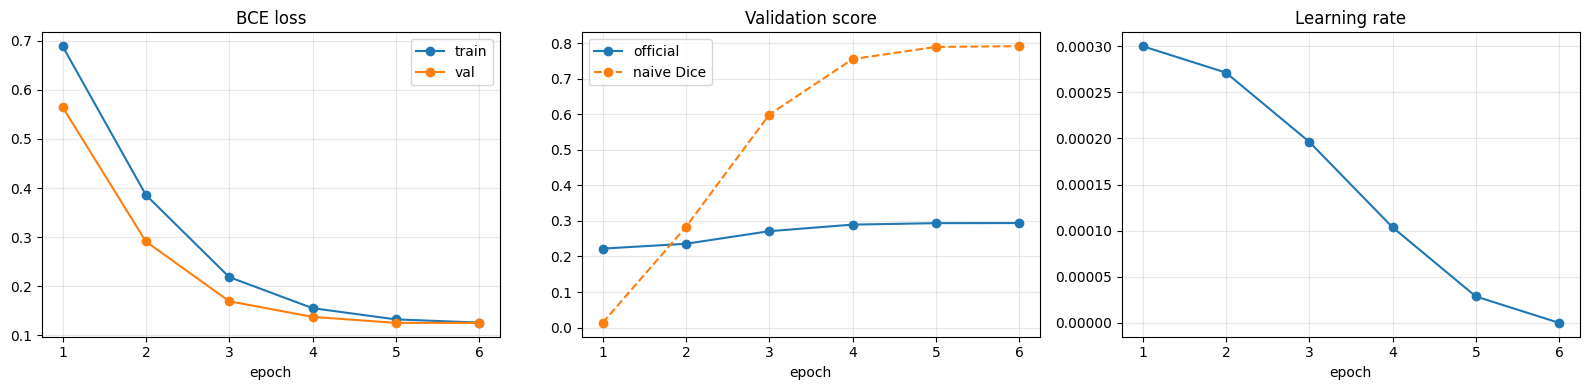

(a) lowest val-loss epoch : 6
(b) best official epoch   : 6  score 0.294
(c) gap at epoch 6        : -0.001

>>> Q8 ANSWER: 6; 6, 0.294; -0.001; Monitor the official validation score; keep epoch 6's checkpoint; pattern: still underfitting


In [15]:
q8a = int(h.loc[h.val_loss.idxmin(), "epoch"])                         # (a) epoch with lowest val loss
q8b_ep = int(h.loc[h.official.idxmax(), "epoch"]); q8b_sc = h.official.max()
q8c = float(h.val_loss.iloc[-1] - h.train_loss.iloc[-1])               # (c) generalization gap at epoch 6

# (d) automatic wording - READ the curves below and edit if the picture says otherwise
last_improving = (h.official.iloc[-1] >= h.official.max() - 1e-9) and (h.val_loss.iloc[-1] <= h.val_loss.min() + 1e-9)
if q8a < 6 and q8c > 0.02 and h.val_loss.iloc[-1] > h.val_loss.min() * 1.05:   pattern = "overfitting"
elif last_improving:                                                           pattern = "still underfitting"
else:                                                                          pattern = "healthy convergence"
q8d = f"Monitor the official validation score; keep epoch {q8b_ep}'s checkpoint; pattern: {pattern}"

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(h.epoch, h.train_loss, "o-", label="train"); ax[0].plot(h.epoch, h.val_loss, "o-", label="val"); ax[0].set_title("BCE loss")
ax[1].plot(h.epoch, h.official, "o-", label="official"); ax[1].plot(h.epoch, h.naive, "o--", label="naive Dice"); ax[1].set_title("Validation score")
ax[2].plot(h.epoch, h.lr, "o-"); ax[2].set_title("Learning rate")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

print(f"(a) lowest val-loss epoch : {q8a}")
print(f"(b) best official epoch   : {q8b_ep}  score {q8b_sc:.3f}")
print(f"(c) gap at epoch 6        : {q8c:.3f}")
answer("Q8", f"{q8a}; {q8b_ep}, {q8b_sc:.3f}; {q8c:.3f}; {q8d}")

## Question 10 — Controlled experimentation (OFAT)
Same split, seed and 6-epoch budget. Each run changes **one** thing relative to R0:

| Run | Change vs R0 |
|---|---|
| **R0** | baseline: constant LR, natural sampling, AMP on (seed 42) |
| **R0b** | identical to R0 but **seed 7** → estimates seed noise |
| **R1** | R0 + warm-up/cosine only (already trained in Q8) |
| **R2** | R0 + bounded-sqrt sampler only (Q3 weights computed on the 960 training images) |

In [16]:
RUNS["R0"]  = train_run("Q10_R0_baseline",       seed=42, sched="none")
RUNS["R0b"] = train_run("Q10_R0b_baseline_seed7", seed=7,  sched="none")
RUNS["R2"]  = train_run("Q10_R2_sqrt_sampler",    seed=42, sched="none", sampler_weights=q3_sampler_weights(train_ids))

[Q10_R0_baseline] ep 1 | train 0.5252 | val_loss 0.3382 | official 0.2363 | fg 0.004 | naive 0.2912 | lr 3.00e-04
[Q10_R0_baseline] ep 2 | train 0.2585 | val_loss 0.2269 | official 0.2842 | fg 0.002 | naive 0.7003 | lr 3.00e-04
[Q10_R0_baseline] ep 3 | train 0.1505 | val_loss 0.1167 | official 0.2936 | fg 0.000 | naive 0.7875 | lr 3.00e-04
[Q10_R0_baseline] ep 4 | train 0.0999 | val_loss 0.0801 | official 0.2965 | fg 0.000 | naive 0.8125 | lr 3.00e-04
[Q10_R0_baseline] ep 5 | train 0.0694 | val_loss 0.0588 | official 0.3000 | fg 0.000 | naive 0.8417 | lr 3.00e-04
[Q10_R0_baseline] ep 6 | train 0.0523 | val_loss 0.0462 | official 0.2998 | fg 0.000 | naive 0.8396 | lr 3.00e-04
[Q10_R0b_baseline_seed7] ep 1 | train 0.4909 | val_loss 1.2655 | official 0.2098 | fg 0.014 | naive 0.0981 | lr 3.00e-04
[Q10_R0b_baseline_seed7] ep 2 | train 0.2265 | val_loss 0.2796 | official 0.2656 | fg 0.000 | naive 0.5615 | lr 3.00e-04
[Q10_R0b_baseline_seed7] ep 3 | train 0.1279 | val_loss 0.0999 | official 

In [17]:
a = {k: RUNS[k]["best"] for k in ["R0", "R0b", "R1", "R2"]}                     # (a) best official val score of each run
noise   = abs(a["R0"] - a["R0b"])                                                # (b) noise band
gain_R1, gain_R2 = a["R1"] - a["R0"], a["R2"] - a["R0"]
c_R1 = "yes" if gain_R1 > 2 * noise else "no"                                    # (c)
c_R2 = "yes" if gain_R2 > 2 * noise else "no"
d_R0 = 100 * false_alarm_rate(RUNS["R0"]["P_best"], G_val)                       # (d) clean-pair false-alarm rate (best ckpt, thr 0.5)
d_R2 = 100 * false_alarm_rate(RUNS["R2"]["P_best"], G_val)

q10e = ("Because the sampler, warm-up/cosine and AMP would all change at once, their effects are confounded, so any score change "
        "could not be attributed to a single component (nor separated from seed noise or interactions).")
if d_R2 > d_R0:
    q10f = ("The false-alarm rate rises from R0 to R2, showing that oversampling defective images shifts the training prior toward "
            "defects, so the model over-predicts defects on clean pairs relative to the true validation prior.")
elif d_R2 < d_R0:
    q10f = ("The false-alarm rate falls from R0 to R2, so the sampling-induced prior shift did not cause extra false alarms here "
            "(the model sees more varied defect examples and stays conservative on clean pairs).")
else:
    q10f = "The false-alarm rate is unchanged between R0 and R2, so the prior shift from sampling had no measurable effect here."

print(f"(a) R0 {a['R0']:.3f} | R0b {a['R0b']:.3f} | R1 {a['R1']:.3f} | R2 {a['R2']:.3f}")
print(f"(b) noise band {noise:.3f} | gain R1 {gain_R1:+.3f} | gain R2 {gain_R2:+.3f}   (2x noise = {2*noise:.3f})")
print(f"(c) R1 > 2x noise: {c_R1} | R2 > 2x noise: {c_R2}")
print(f"(d) false-alarm rate: R0 {d_R0:.1f}% | R2 {d_R2:.1f}%")
answer("Q10", f"{a['R0']:.3f}, {a['R0b']:.3f}, {a['R1']:.3f}, {a['R2']:.3f}; {noise:.3f}, {gain_R1:.3f}, {gain_R2:.3f}; "
              f"{c_R1}, {c_R2}; {d_R0:.1f}, {d_R2:.1f}; {q10e}; {q10f}")

(a) R0 0.300 | R0b 0.308 | R1 0.294 | R2 0.322
(b) noise band 0.008 | gain R1 -0.006 | gain R2 +0.022   (2x noise = 0.016)
(c) R1 > 2x noise: no | R2 > 2x noise: yes
(d) false-alarm rate: R0 0.0% | R2 5.2%

>>> Q10 ANSWER: 0.300, 0.308, 0.294, 0.322; 0.008, -0.006, 0.022; no, yes; 0.0, 5.2; Because the sampler, warm-up/cosine and AMP would all change at once, their effects are confounded, so any score change could not be attributed to a single component (nor separated from seed noise or interactions).; The false-alarm rate rises from R0 to R2, showing that oversampling defective images shifts the training prior toward defects, so the model over-predicts defects on clean pairs relative to the true validation prior.


## Final answer sheet (copy into the Google Form)

In [18]:
for q in [f"Q{i}" for i in range(1, 11)]:
    print(f"{q}: {ANS.get(q, '(not computed - run the cells above)')}\n")
with open("answers.txt", "w") as f:
    for q in [f"Q{i}" for i in range(1, 11)]: f.write(f"{q}: {ANS.get(q, '')}\n")
print("saved answers.txt")

Q1: 578; 107, 35, 438, 181; 15; 578, 1

Q2: 0.0160, 561.5, 6251

Q3: 28.81, 48.17; 104.69, 35.00; 2.99; 10

Q4: 7.50e-05, 1.50e-04, 2.61e-05; 4.00e-05; The LR stays stuck in the tiny warmup range (about 4e-5 at the end, never reaching 3e-4 and never decaying), so the loss falls very slowly and the model underfits with a flat LR curve and no cosine shape.

Q5: 10, 7, 0.671; no, 11

Q6: 400; 2800, 1600; 20, 40; 32; 120, 30; 4; 60

Q7: 4039; 0.8415, 0.3000; 0.6398, 0.8400; Naive Dice, 0.8500

Q8: 6; 6, 0.294; -0.001; Monitor the official validation score; keep epoch 6's checkpoint; pattern: still underfitting

Q9: 5, 99, 657; 99.24; 66.05, 501+; Missed pairs count every defect equally regardless of size, whereas missed pixels are dominated by the few large defects that hold most of the pixels, so the bin with the most small/numerous defects can lose the most pairs while a different bin loses the most pixels.

Q10: 0.300, 0.308, 0.294, 0.322; 0.008, -0.006, 0.022; no, yes; 0.0, 5.2; Becaus